# Original × reconstruído, mapas de erro e exemplos de falhas
## Detecção de anomalias com Autoencoder — Issue #8

**Responsável:** Luiz Wessel (`Wessel2007`). **Etapa da arquitetura:** 13. Visualização dos resultados.

O detector marca uma imagem como anomalia quando o **erro de reconstrução** (MSE por imagem) passa do limiar.
Este notebook mostra, para a apresentação, o Autoencoder **funcionando e falhando**:

1. grades **original | reconstruído | mapa de erro `|x − x̂|`**;
2. as **melhores e piores** reconstruções do teste;
3. **falsos positivos** (normais marcadas como anomalia) e **falsos negativos** (anomalias que passaram como normais);
4. para cada tipo de falha, uma explicação do provável motivo, **medida** e conectada às hipóteses da EDA (#3).

**Protocolo.** Mesmos checkpoints da issue #5 e mesma divisão de dados do treino. O limiar é o **percentil 95 dos erros
da validação** (só imagens normais), a escolha registrada pelo grupo na issue #6 (`reports/avaliacao_deteccao.md`).
A regra é a mesma de `threshold_metrics`: anomalia se `erro > limiar`. O teste é usado aqui apenas para **visualizar e
diagnosticar**; nenhuma decisão do detector é alterada com base nestas figuras.

### 1. Ambiente, configuração e checkpoints

Os checkpoints não são versionados (`models/` está no `.gitignore`). Pesos treinados em outra máquina podem diferir
um pouco, então as contagens de FP/FN podem variar levemente em relação à tabela da issue #6; a seção 2 mostra essa
comparação lado a lado. Os números do texto são aproximados; os exatos estão nas saídas das células.

In [1]:
%matplotlib inline
from dataclasses import replace
from pathlib import Path
import json

import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from autoencoder import reconstructions
from autoencoder.data import CLASS_NAMES, load_config, load_splits, make_dataloaders
from autoencoder.model import Autoencoder
from autoencoder.reconstructions import reconstruct_dataset
from autoencoder.reproducibility import set_seed

# cenário -> (classe anômala, checkpoint treinado SEM essa classe), como em scripts/evaluate.py
SCENARIOS = {"bag": (8, "models/ae_bag.pt"), "sandal": (5, "models/ae_sandal.pt")}

def load_trained_model(config_path, checkpoint):
    """Recria a arquitetura do YAML e carrega os pesos salvos no treino."""
    model = Autoencoder.from_config(config_path)
    model.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True))
    return model.eval()

ROOT = next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p / "configs/default.yaml").is_file() and (p / "pyproject.toml").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Abra o notebook dentro do repositório do projeto.")

CONFIG_PATH = ROOT / "configs/default.yaml"
base_config = load_config(CONFIG_PATH)
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = base_config.seed
set_seed(SEED)

missing = [ckpt for _, ckpt in SCENARIOS.values() if not (ROOT / ckpt).is_file()]
if missing:
    raise FileNotFoundError(
        f"Checkpoints ausentes: {missing}. Treine antes, na raiz do projeto:\n"
        "  python scripts/train_cenarios.py --scenario bag\n"
        "  python scripts/train_cenarios.py --scenario sandal")

def show_and_save(fig, filename):
    """Exibe no notebook e salva em reports/figures/ (fundo branco, para slides)."""
    fig.savefig(FIGURES / filename, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

def load_scenario(name):
    """Mesma divisão de dados do treino e da avaliação, com a classe anômala do cenário."""
    anomaly_class, checkpoint = SCENARIOS[name]
    config = replace(base_config, anomaly_class=anomaly_class)
    splits = load_splits(config)
    loaders = make_dataloaders(splits, config.batch_size, config.num_workers)
    model = load_trained_model(CONFIG_PATH, ROOT / checkpoint)
    return anomaly_class, splits, loaders, model

print(f"Seed: {SEED} | latent_dim: {load_trained_model(CONFIG_PATH, ROOT / SCENARIOS['bag'][1]).latent_dim}")
print("Cenários:", {name: CLASS_NAMES[c] for name, (c, _) in SCENARIOS.items()})

from sklearn.neighbors import NearestNeighbors
from autoencoder.evaluate import choose_threshold, threshold_metrics, ranking_metrics

PERCENTILE = 95          # decisão do grupo na issue #6
ERROR_VMAX = 1.0         # escala fixa dos mapas |x − x̂|: comparável entre todas as figuras
N_EXAMPLES = 8

Seed: 42 | latent_dim: 16
Cenários: {'bag': 'Bag', 'sandal': 'Sandal'}


### 2. Reconstruções, limiar e conferência com a avaliação da issue #6

Para cada cenário: reconstruímos validação e teste, calculamos o limiar **só com a validação** e classificamos o teste
em TP, FN, FP e TN. A tabela compara as métricas desta execução com as gravadas em `reports/resultados_deteccao.csv`.

In [2]:
import csv

committed = {(r["cenario"], int(r["percentil"])): r
             for r in csv.DictReader((ROOT / "reports/resultados_deteccao.csv").open(encoding="utf-8"))}

scenarios, comparison = {}, []
for name in SCENARIOS:
    anomaly_class, splits, loaders, model = load_scenario(name)
    val = reconstruct_dataset(model, loaders["val"])
    test = reconstruct_dataset(model, loaders["test"])
    assert not (val["labels"] == anomaly_class).any(), "A validação não pode conter a classe anômala"
    np.testing.assert_array_equal(test["labels"], splits.test.labels)

    threshold = choose_threshold(val["mse"], PERCENTILE)  # só validação!
    is_anomaly = test["labels"] == anomaly_class
    flagged = test["mse"] > threshold
    groups = {"TP": flagged & is_anomaly, "FN": ~flagged & is_anomaly,
              "FP": flagged & ~is_anomaly, "TN": ~flagged & ~is_anomaly}
    scenarios[name] = {
        "anomaly_class": anomaly_class, "threshold": threshold, "test": test,
        "is_anomaly": is_anomaly, "groups": groups,
        "latent_test": test["latent"],
        "latent_val": val,
    }
    metrics = {**ranking_metrics(test["mse"], is_anomaly.astype(int)),
               **threshold_metrics(test["mse"], is_anomaly.astype(int), threshold)}
    assert metrics["fp"] == groups["FP"].sum() and metrics["fn"] == groups["FN"].sum()
    old = committed[(name, PERCENTILE)]
    for key in ("limiar", "roc_auc", "pr_auc", "precision", "recall", "tp", "fn", "fp", "tn"):
        now = threshold if key == "limiar" else metrics[key]
        fmt = "{:.0f}" if key in ("tp", "fn", "fp", "tn") else "{:.4f}"
        comparison.append(f"| {name} | {key} | {fmt.format(float(old[key]))} | {fmt.format(now)} |")

display(Markdown("\n".join([f"**Limiar P{PERCENTILE} da validação e métricas no teste**", "",
                            "| Cenário | Métrica | Issue #6 (commitado) | Esta execução |",
                            "|---|---|---:|---:|", *comparison])))

**Limiar P95 da validação e métricas no teste**

| Cenário | Métrica | Issue #6 (commitado) | Esta execução |
|---|---|---:|---:|
| bag | limiar | 0.0244 | 0.0244 |
| bag | roc_auc | 0.9516 | 0.9516 |
| bag | pr_auc | 0.5972 | 0.5972 |
| bag | precision | 0.5992 | 0.5992 |
| bag | recall | 0.7100 | 0.7100 |
| bag | tp | 710 | 710 |
| bag | fn | 290 | 290 |
| bag | fp | 475 | 475 |
| bag | tn | 8525 | 8525 |
| sandal | limiar | 0.0246 | 0.0246 |
| sandal | roc_auc | 0.8955 | 0.8955 |
| sandal | pr_auc | 0.4523 | 0.4523 |
| sandal | precision | 0.4672 | 0.4672 |
| sandal | recall | 0.4060 | 0.4060 |
| sandal | tp | 406 | 406 |
| sandal | fn | 594 | 594 |
| sandal | fp | 463 | 463 |
| sandal | tn | 8537 | 8537 |

### 3. Como ler as grades

Cada coluna é uma imagem do teste. **Linha 1:** original. **Linha 2:** reconstrução do Autoencoder. **Linha 3:** mapa
de erro absoluto por pixel `|x − x̂|`: preto = reconstruído perfeitamente, amarelo = erro máximo. Todos os mapas usam a
**mesma escala fixa de 0 a 1**, então dá para comparar brilho entre figuras diferentes. O título traz a classe
verdadeira e o MSE da imagem; o limiar do cenário aparece no título da figura.

#### 3.1. Um exemplo por classe (sorteado)

Antes dos extremos, uma visão "típica": uma imagem sorteada de cada classe. A anomalia está marcada com `*`.

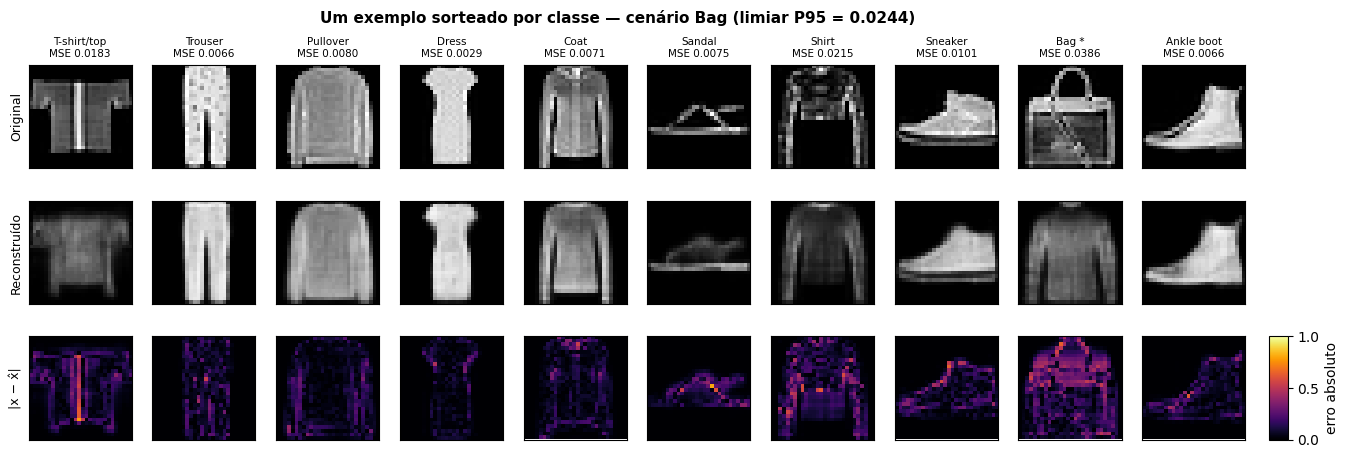

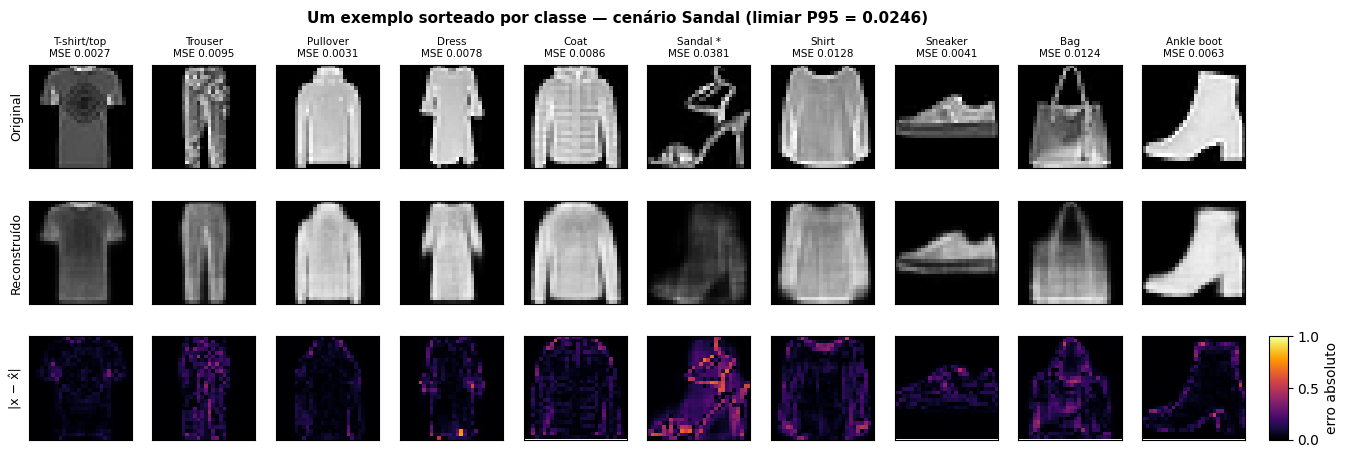

In [3]:
rng = np.random.default_rng(SEED)

def caption(s, i):
    y = int(s["test"]["labels"][i])
    star = " *" if y == s["anomaly_class"] else ""
    return f"{CLASS_NAMES[y]}{star}\nMSE {s['test']['mse'][i]:.4f}"

def grid(s, indices, title, filename):
    t = s["test"]
    fig = reconstructions.plot_reconstruction_grid(
        t["images"][indices], t["reconstructions"][indices], [caption(s, i) for i in indices],
        title=f"{title} — cenário {CLASS_NAMES[s['anomaly_class']]} (limiar P{PERCENTILE} = {s['threshold']:.4f})",
        error_vmax=ERROR_VMAX)
    show_and_save(fig, filename)

for name, s in scenarios.items():
    labels = s["test"]["labels"]
    one_per_class = np.array([rng.choice(np.flatnonzero(labels == c)) for c in range(10)])
    grid(s, one_per_class, "Um exemplo sorteado por classe", f"recon_por_classe_{name}.png")

### 4. Melhores e piores reconstruções do teste

Os 8 menores e os 8 maiores MSE entre as 10.000 imagens de teste (normais e anômalas). Abaixo das figuras, a
composição por classe das 100 melhores e das 100 piores, para não tirar conclusões de só 8 exemplos.

[bag] 100 melhores: Trouser 81, T-shirt/top 10, Dress 3, Pullover 2, Shirt 2, Coat 1, Sneaker 1
[bag] 100 piores: Bag 60, Sandal 12, T-shirt/top 8, Pullover 7, Shirt 7, Trouser 2, Dress 2, Coat 1, Ankle boot 1
[sandal] 100 melhores: Trouser 93, T-shirt/top 3, Pullover 2, Shirt 1, Sneaker 1
[sandal] 100 piores: Sandal 71, T-shirt/top 6, Pullover 6, Bag 6, Shirt 5, Trouser 2, Dress 2, Coat 1, Ankle boot 1


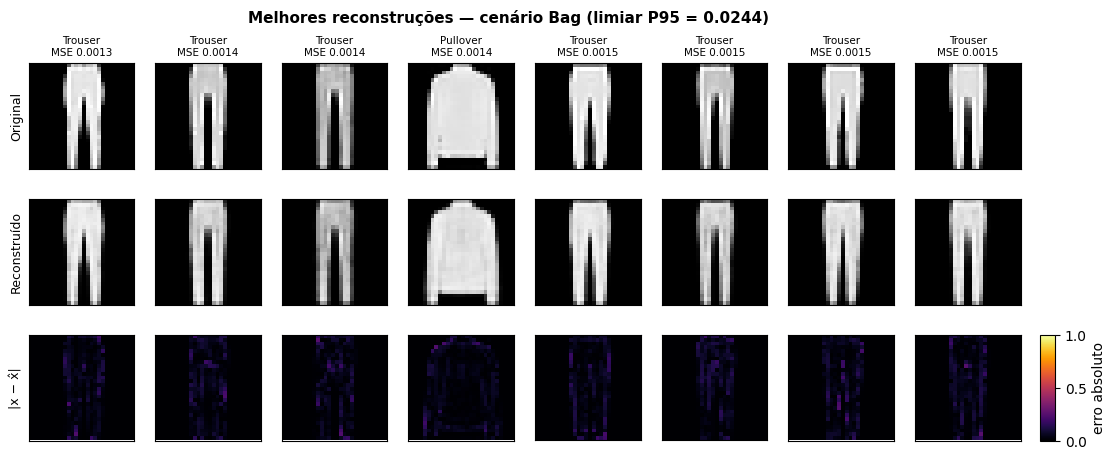

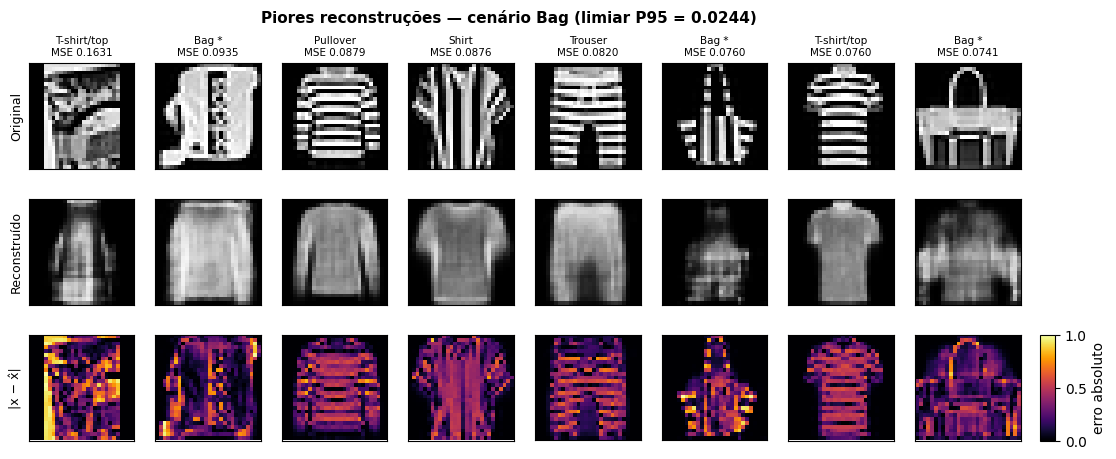

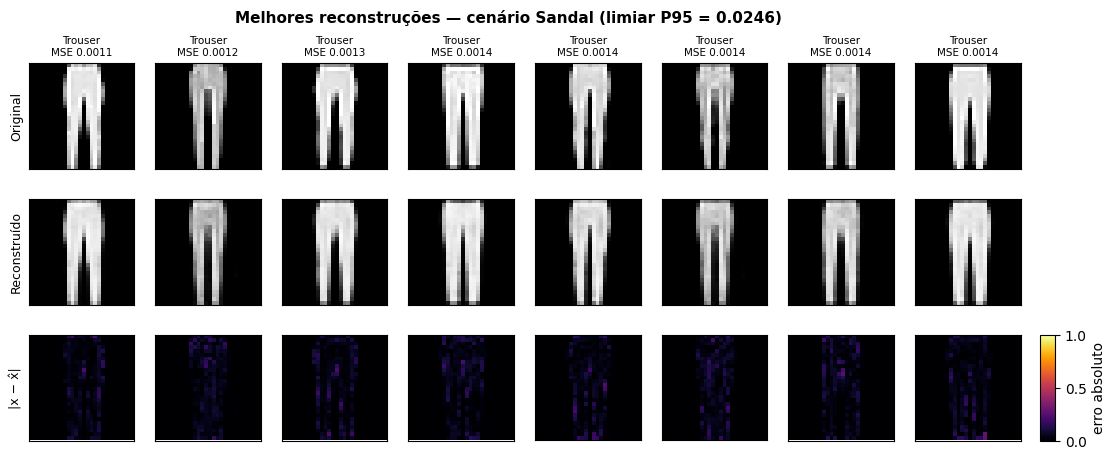

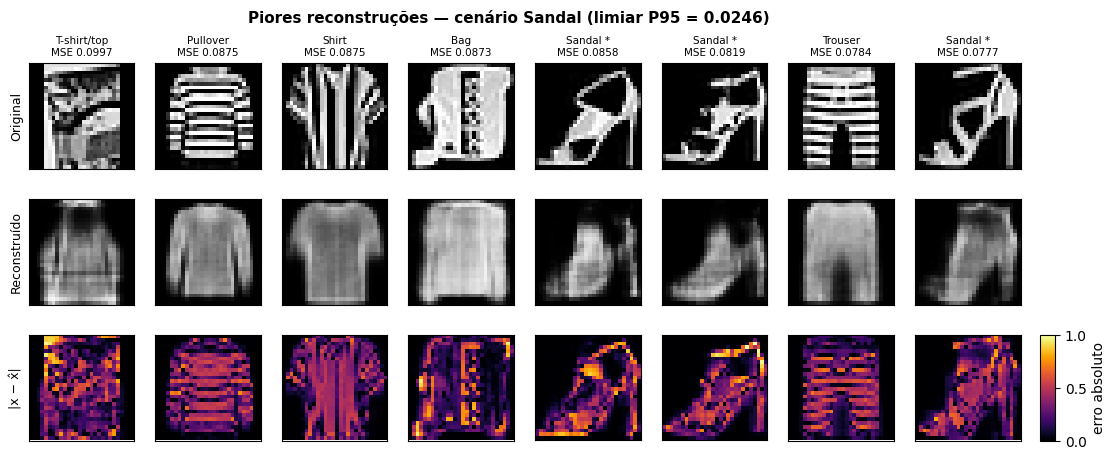

In [4]:
for name, s in scenarios.items():
    errors, labels = s["test"]["mse"], s["test"]["labels"]
    grid(s, reconstructions.extreme_indices(errors, N_EXAMPLES, largest=False), "Melhores reconstruções",
         f"recon_melhores_{name}.png")
    grid(s, reconstructions.extreme_indices(errors, N_EXAMPLES, largest=True), "Piores reconstruções",
         f"recon_piores_{name}.png")
    for label, largest in (("100 melhores", False), ("100 piores", True)):
        top = labels[reconstructions.extreme_indices(errors, 100, largest=largest)]
        counts = {CLASS_NAMES[c]: int((top == c).sum()) for c in np.unique(top)}
        print(f"[{name}] {label}: " + ", ".join(f"{k} {v}" for k, v in sorted(counts.items(), key=lambda kv: -kv[1])))

### 5. Falsos positivos: normais marcadas como anomalia

Primeiro os **8 FP mais extremos** (maior erro): os alarmes falsos mais "convictos". Depois uma **amostra sorteada** de
8 FP, que representa melhor o FP típico (os extremos tendem a ser casos raros).

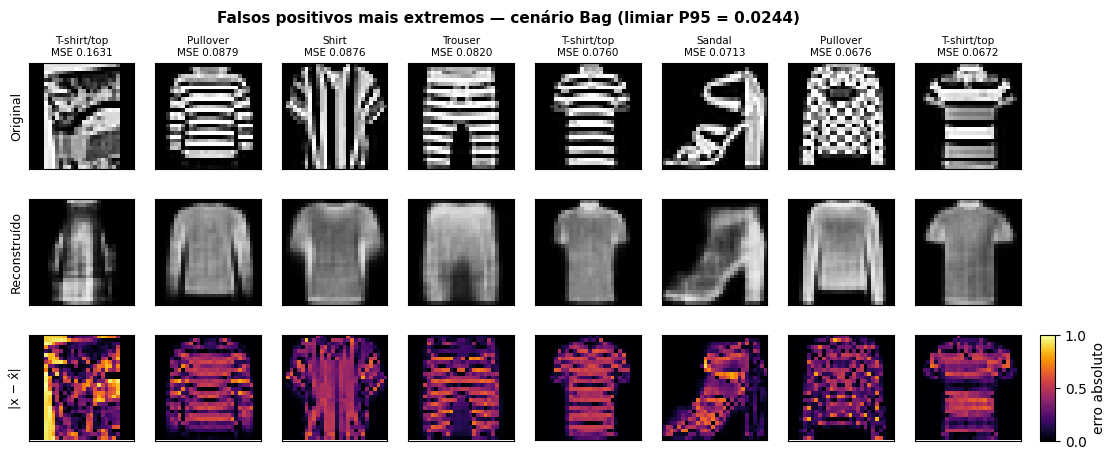

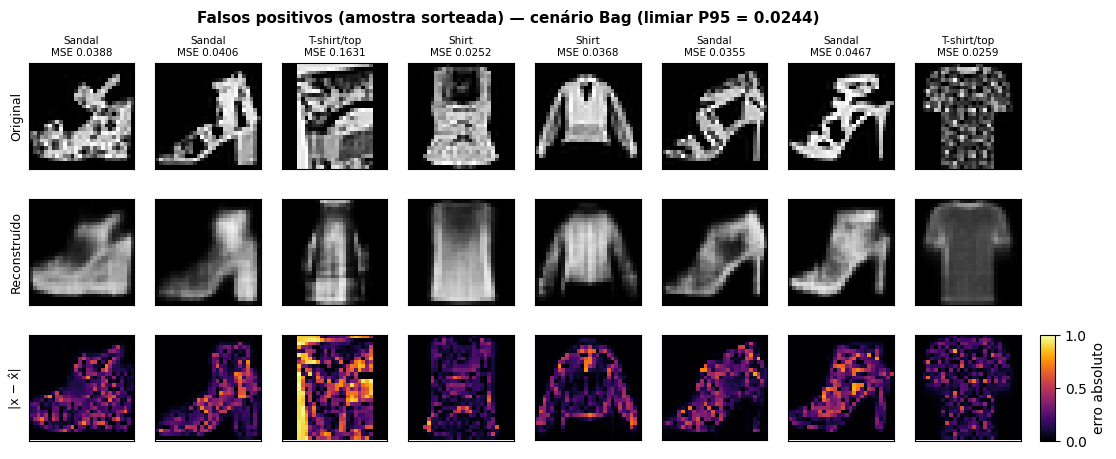

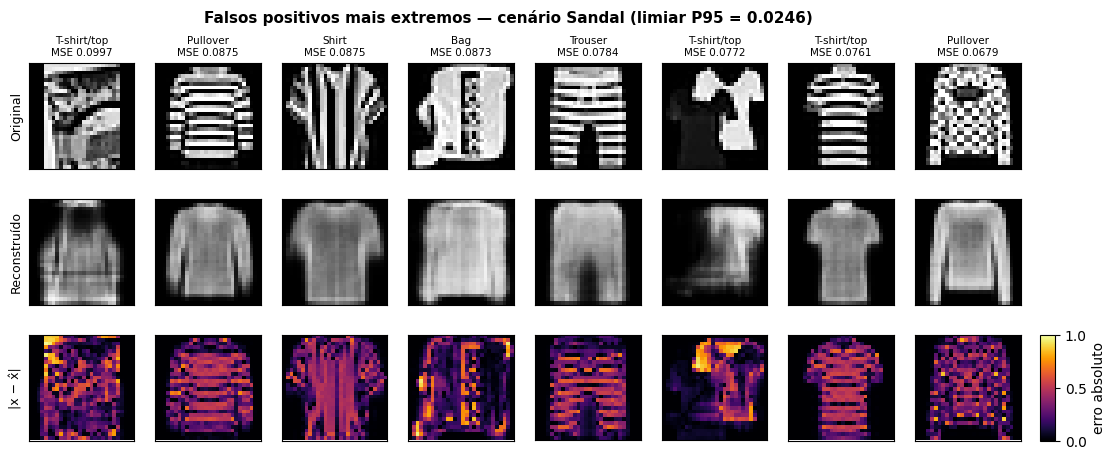

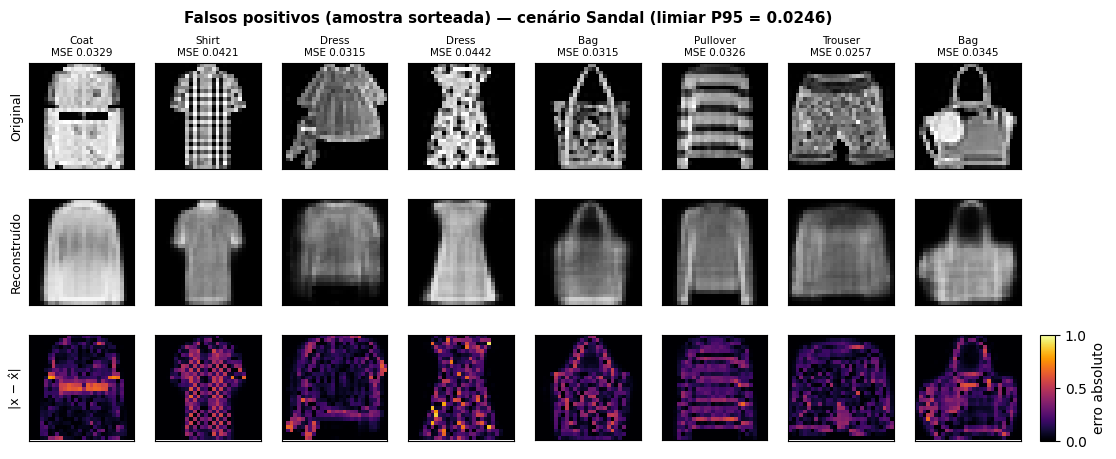

In [5]:
for name, s in scenarios.items():
    failures = reconstructions.failure_indices(s["test"]["mse"], s["is_anomaly"], s["threshold"], N_EXAMPLES)
    s["failures"] = failures
    grid(s, failures["fp"], "Falsos positivos mais extremos", f"falsos_positivos_{name}.png")
    sample = np.sort(rng.choice(np.flatnonzero(s["groups"]["FP"]), N_EXAMPLES, replace=False))
    grid(s, sample, "Falsos positivos (amostra sorteada)", f"falsos_positivos_{name}_amostra.png")

### 6. Falsos negativos: anomalias que passaram como normais

Primeiro os **8 FN mais bem escondidos** (menor erro); depois uma **amostra sorteada** de 8 FN.

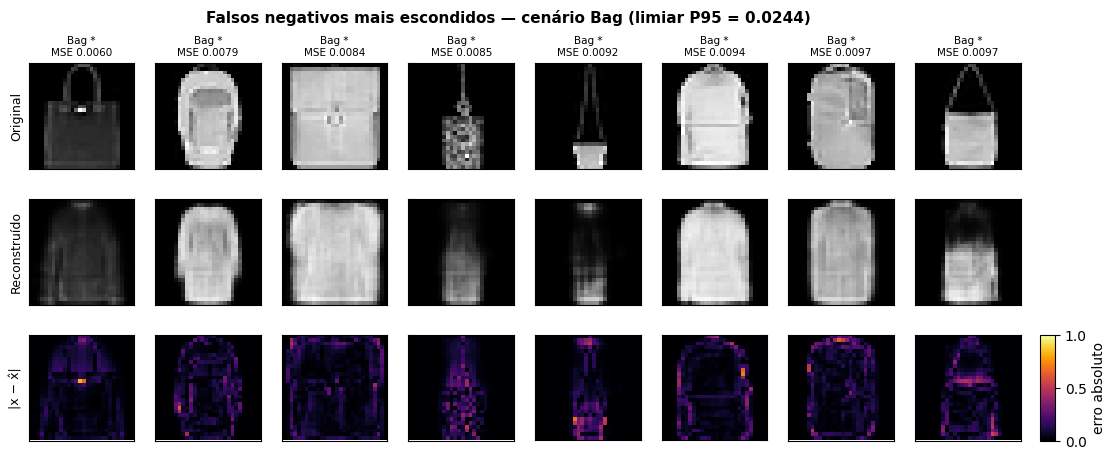

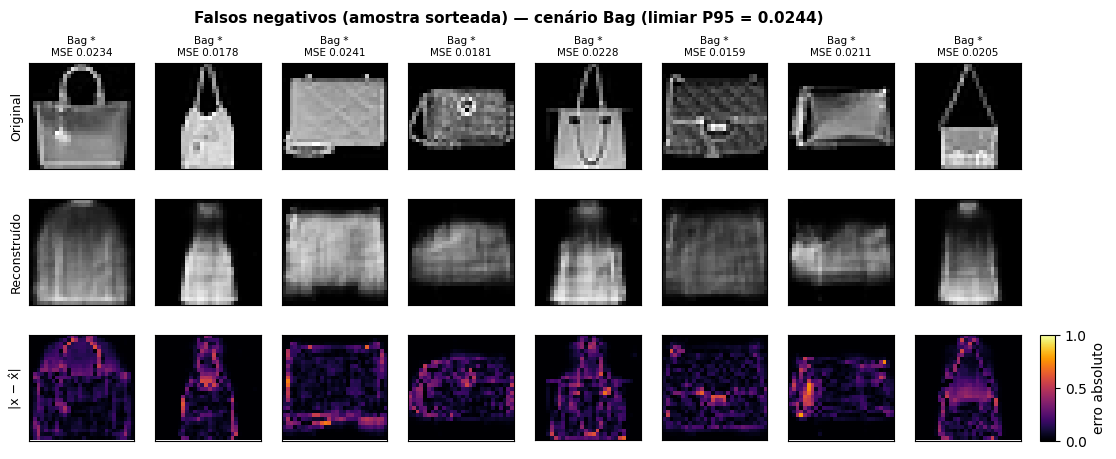

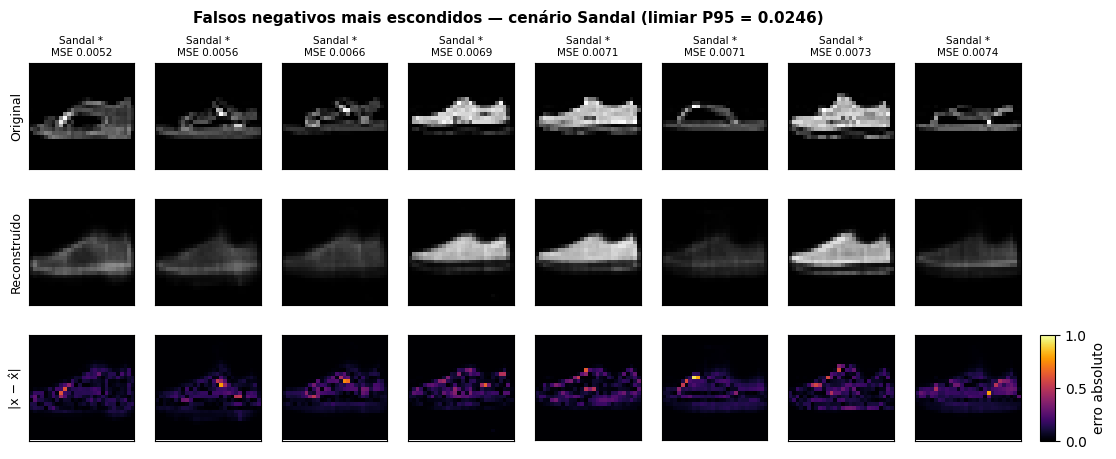

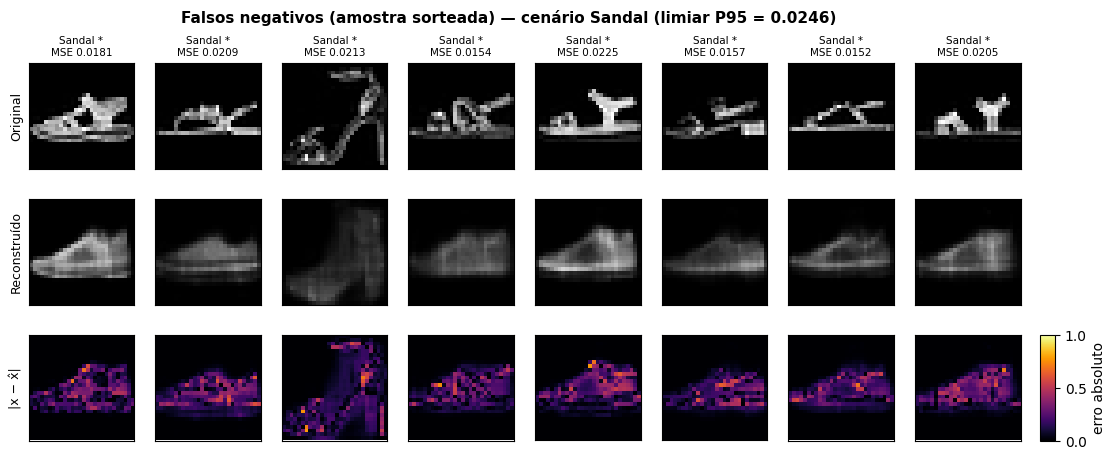

In [6]:
for name, s in scenarios.items():
    failures = s["failures"]
    grid(s, failures["fn"], "Falsos negativos mais escondidos", f"falsos_negativos_{name}.png")
    sample = np.sort(rng.choice(np.flatnonzero(s["groups"]["FN"]), N_EXAMPLES, replace=False))
    grid(s, sample, "Falsos negativos (amostra sorteada)", f"falsos_negativos_{name}_amostra.png")

### 7. Medindo os motivos das falhas

As figuras sugerem explicações; aqui elas viram números, calculados para os quatro grupos (TP, FN, FP, TN):

- **Intensidade média** e **fração de fundo** (pixels exatamente 0): as medidas da EDA.
- **Fração do objeto**: pixels com valor > 0.
- **MSE só no objeto**: o erro médio calculado apenas nos pixels do objeto, sem o fundo preto.
- **Textura**: variação média entre pixels vizinhos (`|Δx| + |Δy|`). Listras, xadrez e estampas têm valores altos.
- **Classe normal mais próxima no latente**: classe majoritária entre os 10 vizinhos mais próximos na **validação**
  (só normais). Mostra com o que o modelo "confunde" a imagem.

In [7]:
def image_stats(images, reconstructions):
    flat = images.reshape(len(images), -1)
    obj = images > 0
    squared = (reconstructions - images) ** 2
    return {
        "intensidade": flat.mean(1),
        "fundo": (flat == 0).mean(1),
        "objeto": obj.mean((1, 2)),
        "mse_objeto": (squared * obj).sum((1, 2)) / np.maximum(obj.sum((1, 2)), 1),
        "textura": np.abs(np.diff(images, axis=1)).mean((1, 2)) + np.abs(np.diff(images, axis=2)).mean((1, 2)),
    }

def nearest_normal_class(s, mask, k=10):
    reference = s["latent_val"]
    neighbors = NearestNeighbors(n_neighbors=k).fit(reference["latent"]).kneighbors(
        s["latent_test"][mask], return_distance=False)
    majority = np.array([np.bincount(row, minlength=10).argmax() for row in reference["labels"][neighbors]])
    return {CLASS_NAMES[c]: float((majority == c).mean()) for c in np.unique(majority)}

for name, s in scenarios.items():
    t = s["test"]
    stats = image_stats(t["images"], t["reconstructions"])
    s["stats"] = stats
    lines = [f"**Cenário {CLASS_NAMES[s['anomaly_class']]}** (limiar = {s['threshold']:.4f})", "",
             "| Grupo | n | MSE (mediana) | Intensidade | Fundo | Objeto | MSE só no objeto (mediana) | Textura (mediana) |",
             "|---|---:|---:|---:|---:|---:|---:|---:|"]
    for g, mask in s["groups"].items():
        lines.append(f"| {g} | {mask.sum()} | {np.median(t['mse'][mask]):.4f} | {stats['intensidade'][mask].mean():.3f} | "
                     f"{stats['fundo'][mask].mean():.1%} | {np.median(stats['objeto'][mask]):.1%} | "
                     f"{np.median(stats['mse_objeto'][mask]):.4f} | {np.median(stats['textura'][mask]):.3f} |")
    display(Markdown("\n".join(lines)))

    above = {g: float((stats["mse_objeto"][s["groups"][g]] > s["threshold"]).mean()) for g in ("FN", "TN")}
    s["objeto_acima_limiar"] = above
    print(f"Se o erro fosse medido só no objeto, passariam do limiar: {above['FN']:.1%} dos FN e {above['TN']:.1%} dos TN.")

    labels = t["labels"]
    fp_rate = {CLASS_NAMES[c]: (int((s["groups"]["FP"] & (labels == c)).sum()), float((s["groups"]["FP"] & (labels == c)).sum() / (labels == c).sum()))
               for c in range(10) if c != s["anomaly_class"]}
    s["fp_por_classe"] = fp_rate
    print("FP por classe (quantidade, % da classe):",
          ", ".join(f"{k} {n} ({r:.1%})" for k, (n, r) in sorted(fp_rate.items(), key=lambda kv: -kv[1][0])))
    for g in ("FN", "TP"):
        near = nearest_normal_class(s, s["groups"][g])
        s[f"vizinho_{g}"] = near
        print(f"{g}: classe normal mais próxima no latente → " +
              ", ".join(f"{k} {v:.1%}" for k, v in sorted(near.items(), key=lambda kv: -kv[1]) if v >= 0.02))
    print()

Se o erro fosse medido só no objeto, passariam do limiar: 73.8% dos FN e 20.0% dos TN.
FP por classe (quantidade, % da classe): Sandal 166 (16.6%), Shirt 77 (7.7%), T-shirt/top 62 (6.2%), Pullover 48 (4.8%), Dress 48 (4.8%), Coat 36 (3.6%), Ankle boot 18 (1.8%), Trouser 12 (1.2%), Sneaker 8 (0.8%)
FN: classe normal mais próxima no latente → Shirt 26.6%, Dress 21.4%, Sandal 18.6%, Pullover 13.1%, Coat 11.7%, T-shirt/top 5.9%, Sneaker 2.1%
TP: classe normal mais próxima no latente → Shirt 28.0%, Pullover 23.5%, Coat 19.3%, Sandal 10.4%, Ankle boot 6.8%, Dress 6.6%, T-shirt/top 3.0%, Sneaker 2.1%

Se o erro fosse medido só no objeto, passariam do limiar: 96.5% dos FN e 13.6% dos TN.
FP por classe (quantidade, % da classe): Bag 166 (16.6%), Shirt 68 (6.8%), T-shirt/top 55 (5.5%), Pullover 46 (4.6%), Dress 45 (4.5%), Coat 39 (3.9%), Ankle boot 25 (2.5%), Trouser 10 (1.0%), Sneaker 9 (0.9%)
FN: classe normal mais próxima no latente → Sneaker 81.3%, Ankle boot 12.8%, Bag 2.7%
TP: classe norma

**Cenário Bag** (limiar = 0.0244)

| Grupo | n | MSE (mediana) | Intensidade | Fundo | Objeto | MSE só no objeto (mediana) | Textura (mediana) |
|---|---:|---:|---:|---:|---:|---:|---:|
| TP | 710 | 0.0336 | 0.377 | 39.2% | 60.6% | 0.0434 | 0.178 |
| FN | 290 | 0.0204 | 0.295 | 45.8% | 53.7% | 0.0292 | 0.140 |
| FP | 475 | 0.0306 | 0.279 | 46.2% | 53.8% | 0.0494 | 0.229 |
| TN | 8525 | 0.0074 | 0.279 | 51.2% | 49.1% | 0.0139 | 0.146 |

**Cenário Sandal** (limiar = 0.0246)

| Grupo | n | MSE (mediana) | Intensidade | Fundo | Objeto | MSE só no objeto (mediana) | Textura (mediana) |
|---|---:|---:|---:|---:|---:|---:|---:|
| TP | 406 | 0.0352 | 0.178 | 61.4% | 38.9% | 0.0654 | 0.181 |
| FN | 594 | 0.0170 | 0.108 | 72.1% | 27.4% | 0.0439 | 0.123 |
| FP | 463 | 0.0305 | 0.333 | 39.5% | 60.7% | 0.0431 | 0.236 |
| TN | 8537 | 0.0075 | 0.302 | 48.5% | 53.7% | 0.0135 | 0.148 |

### 8. Por que o detector erra: explicações conectadas à EDA (#3)

Antes do treino, a EDA registrou três hipóteses: **(H1)** Bag pode ter maior erro de reconstrução; **(H2)** Sandal pode ter
mais falsos negativos, porque o fundo preto (≈ 68% dos pixels da Sandal são zero) pode reduzir o erro médio mesmo
quando o objeto é mal reconstruído; **(H3)** imagens incomuns das classes normais podem gerar falsos positivos. Também
apontou semelhanças entre as **classes de calçados** e entre as **peças de parte superior**.

#### Funcionando: melhores e piores reconstruções

- As melhores reconstruções são todas **Trouser**: silhueta simples, quase sempre igual e com pouca textura.
  Junto com Sneaker, é uma das classes com menos FP (≈ 1%).
- As piores são dominadas pela classe anômala (≈ 60 das 100 piores são Bag no cenário Bag; ≈ 70 são Sandal no
  cenário Sandal). É o comportamento esperado do detector e confirma **H1** no cenário Bag. O restante são roupas
  com listras e estampas, que levam aos falsos positivos abaixo.

#### Falsos negativos da Sandal: o fundo dilui o erro e o modelo "desenha um tênis" (H2 confirmada)

- O cenário Sandal tem **cerca do dobro de FN** do cenário Bag (≈ 590 contra ≈ 290 com o mesmo P95).
- As sandálias que escapam são as **mais vazadas**: o objeto ocupa só ≈ 27% da imagem (≈ 54% nas normais corretamente
  aceitas) e a intensidade média é a mais baixa de todos os grupos (≈ 0,11).
- O erro **no objeto** dessas sandálias é alto: mediana ≈ 0,044, acima do limiar (≈ 0,025). Medido só no objeto,
  **≈ 96% dos FN passariam do limiar**, contra ≈ 14% das normais corretas. O que esconde a anomalia é a **média sobre
  784 pixels, a maioria fundo preto bem reconstruído**: exatamente o mecanismo de H2.
- Nas grades, o decodificador reconstrói sandálias de tiras como **um tênis fechado e borrado**. No espaço latente,
  ≈ 81% dos FN têm Sneaker como classe normal mais próxima. As sandálias detectadas (TP) ficam mais perto de
  Ankle boot (≈ 74%): são as de salto ou cano alto, com mais área e brilho, que o modelo não consegue imitar.
  É a semelhança entre calçados apontada pela EDA e visível em `03_latent_space.ipynb` (#7).

#### Falsos negativos da Bag: bolsas com cara de roupa

- O padrão mais claro nas grades é a **silhueta**: sacolas e mochilas de corpo retangular e cor uniforme são
  reconstruídas como **regatas, blusas ou vestidos**. As alças finas somem, mas o corpo, que é a maior parte do objeto,
  sai parecido o bastante para o erro ficar abaixo do limiar.
- Em média, essas bolsas têm **menos intensidade e menos textura** que as detectadas (intensidade ≈ 0,30 contra ≈ 0,38;
  textura ≈ 0,14 contra ≈ 0,18): superfícies lisas são fáceis de imitar com a "média" de uma roupa.
- No latente, os FN da Bag ficam perto de Shirt, Dress, Sandal, Pullover e Coat: não há uma única classe que "absorva"
  a bolsa, e sim formas parecidas espalhadas.
- A diluição pelo fundo também existe aqui, mas é menor (≈ 74% dos FN passariam do limiar no objeto, contra ≈ 20% das
  normais corretas). A EDA já alertava que a Bag não deveria ser tratada como separável só pelo brilho
  (média 0,35, sobreposta à das roupas).

#### Falsos positivos: textura que o gargalo não comporta e classes muito variadas (H3 confirmada)

- Os FP têm a **maior textura** de todos os grupos (≈ 0,23 contra ≈ 0,15 nas normais corretas). Nas grades: **listras,
  xadrez, estampas e fotos**. Com 16 números no gargalo, o Autoencoder guarda a silhueta e devolve uma versão "média"
  e lisa da peça; cada listra vira uma faixa de erro no mapa `|x − x̂|`. São as "imagens incomuns das classes normais"
  previstas em H3: a peça é normal, o padrão é que é raro.
- Em cada cenário, a **maior fonte de FP é a outra classe difícil**: Sandal no cenário Bag (≈ 17% das sandálias
  normais disparam alarme) e Bag no cenário Sandal (≈ 17% das bolsas). Mesmo vistas no treino, são as classes com
  **maior variedade de formas**: sandálias de tiras finas em muitas configurações, bolsas com e sem alça, de vários
  formatos. A tabela de erro por classe da issue #6 já mostrava a Bag normal com o maior erro entre as normais.
  Nas grades, a alça fina é justamente onde o erro se concentra.
- Shirt e T-shirt/top vêm em seguida (≈ 5–8%), coerente com serem as classes mais misturadas no latente (#7).

#### O que levar para a apresentação

O erro de reconstrução é **um MSE médio sobre a imagem inteira**. Isso explica os dois tipos de falha: **anomalias
pequenas sobre fundo preto** (sandálias vazadas) ficam abaixo do limiar, e **normais com textura fina** (listras)
ficam acima. A medida "MSE só no objeto" mostra que existe sinal que o MSE global desperdiça. Porém ela foi calculada
olhando o teste: trocar o escore exigiria definir e calibrar a nova regra **só com a validação**, e medi-la em dados novos.

### 9. Resumo reproduzível

Os números deste notebook vão para `reports/reconstructions_summary.json`.

In [8]:
def r4(x):
    return round(float(x), 4)

summary = {"fonte": "reconstruct_dataset() sobre validação (limiar) e teste oficial (visualização)",
           "seed": SEED, "percentil_limiar": PERCENTILE, "escala_mapa_erro": [0.0, ERROR_VMAX], "cenarios": {}}
for name, s in scenarios.items():
    t, st = s["test"], s["stats"]
    summary["cenarios"][name] = {
        "classe_anomala": CLASS_NAMES[s["anomaly_class"]],
        "limiar": r4(s["threshold"]),
        "contagens": {g: int(m.sum()) for g, m in s["groups"].items()},
        "por_grupo": {g: {"mse_mediana": r4(np.median(t["mse"][m])), "intensidade_media": r4(st["intensidade"][m].mean()),
                          "fundo_medio": r4(st["fundo"][m].mean()), "objeto_mediana": r4(np.median(st["objeto"][m])),
                          "mse_objeto_mediana": r4(np.median(st["mse_objeto"][m])), "textura_mediana": r4(np.median(st["textura"][m]))}
                      for g, m in s["groups"].items()},
        "mse_objeto_acima_do_limiar": {g: r4(v) for g, v in s["objeto_acima_limiar"].items()},
        "fp_por_classe": {k: {"n": n, "taxa": r4(r)} for k, (n, r) in s["fp_por_classe"].items()},
        "classe_normal_mais_proxima_latente": {g: {k: r4(v) for k, v in s[f"vizinho_{g}"].items()} for g in ("FN", "TP")},
        "indices_teste": {"fp_extremos": s["failures"]["fp"].tolist(), "fn_extremos": s["failures"]["fn"].tolist()},
    }
summary["figuras"] = sorted(f"reports/figures/{p.name}" for p in FIGURES.glob("*.png")
                            if p.name.startswith(("recon_", "falsos_")))
path = ROOT / "reports/reconstructions_summary.json"
path.write_text(json.dumps(summary, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print("Resumo salvo em", path.relative_to(ROOT).as_posix())
print(len(summary["figuras"]), "figuras:", [p.split("/")[-1] for p in summary["figuras"]])

Resumo salvo em reports/reconstructions_summary.json
14 figuras: ['falsos_negativos_bag.png', 'falsos_negativos_bag_amostra.png', 'falsos_negativos_sandal.png', 'falsos_negativos_sandal_amostra.png', 'falsos_positivos_bag.png', 'falsos_positivos_bag_amostra.png', 'falsos_positivos_sandal.png', 'falsos_positivos_sandal_amostra.png', 'recon_melhores_bag.png', 'recon_melhores_sandal.png', 'recon_piores_bag.png', 'recon_piores_sandal.png', 'recon_por_classe_bag.png', 'recon_por_classe_sandal.png']


### 10. Limitações

- Um único treino por cenário, com uma seed; os exemplos exatos de FP/FN mudam se o modelo for retreinado, mas
  os padrões (fundo, textura, classes variadas) é que devem ser comparados.
- As explicações são **diagnósticos** sobre o teste, não novas regras de decisão; nada aqui alterou o limiar.
- Os extremos (8 imagens) podem ser casos raros, por isso as amostras sorteadas e as tabelas acompanham cada figura.